In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import convolution_1D as convo
import plot
import stimulationProtocols


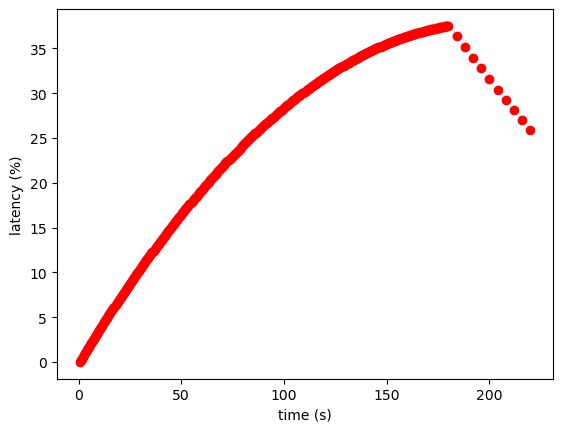

In [2]:
#2Hz
impulses=stimulationProtocols.setStimulationProtocol(15)
simLatency=convo.convolution_1D(impulses, 0.1, 230, convo.memory_1D, plot=False)

plt.scatter(impulses, simLatency, color="red")
plt.xlabel('time (s)')
plt.ylabel('latency (%)')
plt.show()

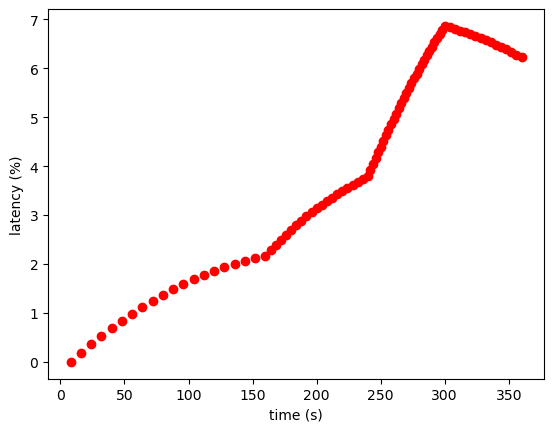

In [3]:
#ELID
impulses=stimulationProtocols.setStimulationProtocol(11)
simLatency=convo.convolution_1D(impulses,0.1,390, convo.memory_1D, plot=False)

plt.scatter(impulses, simLatency, color="red")
plt.xlabel('time (s)')
plt.ylabel('latency (%)')
plt.show()


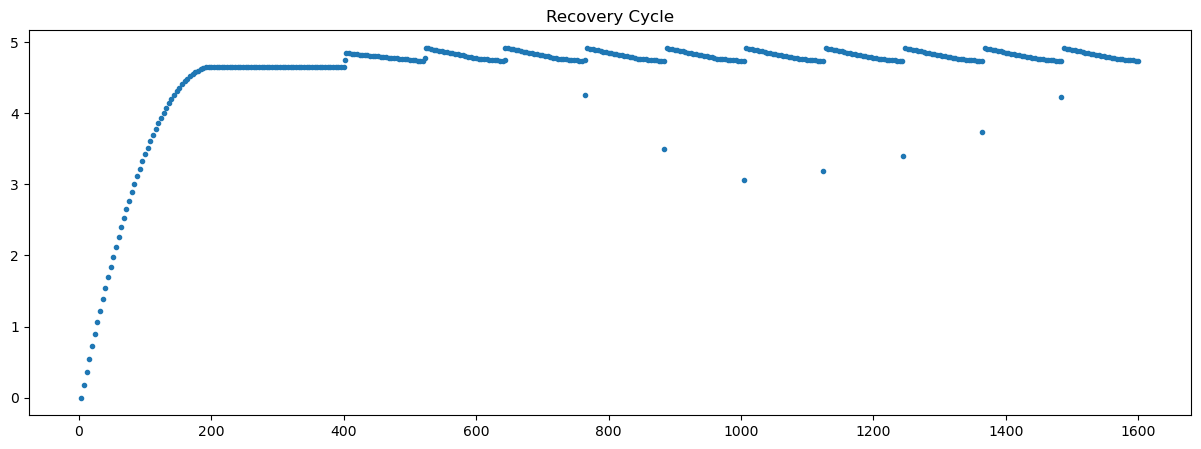

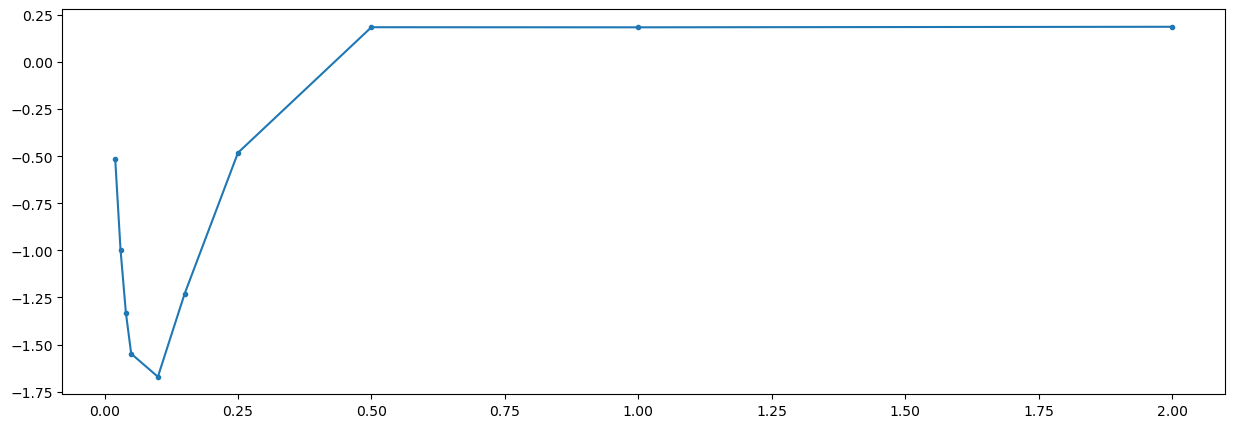

In [4]:
#Recovery Cycle
data_stim=stimulationProtocols.setStimulationProtocol("DP")
relLatency=convo.convolution_1D(data_stim,0.01,1650, convo.memory_1D, "Recovery Cycle", plot=False)
    
plt.figure(figsize=(15,5)) 
plt.plot(data_stim, relLatency, marker='.', linestyle='none')
plt.title("Recovery Cycle")
plt.show()

plt.figure(figsize=(15,5))
extras=[2, 1, 0.5, 0.25, 0.15, 0.1, 0.05, 0.04, 0.03, 0.02]#distance to next regular puls
plt.plot(extras[::-1], plot.getRecoveryCycle(relLatency)[::-1], marker='.')
plt.show()

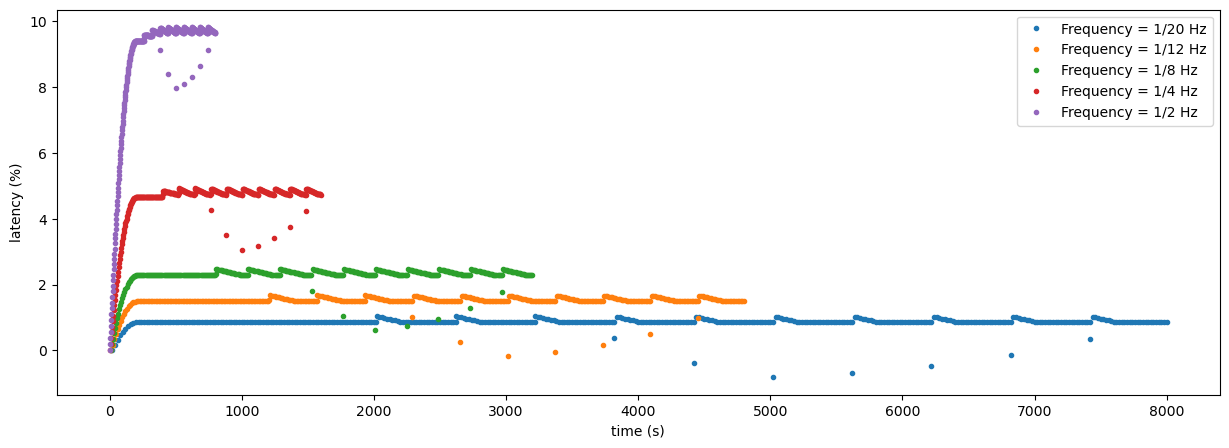

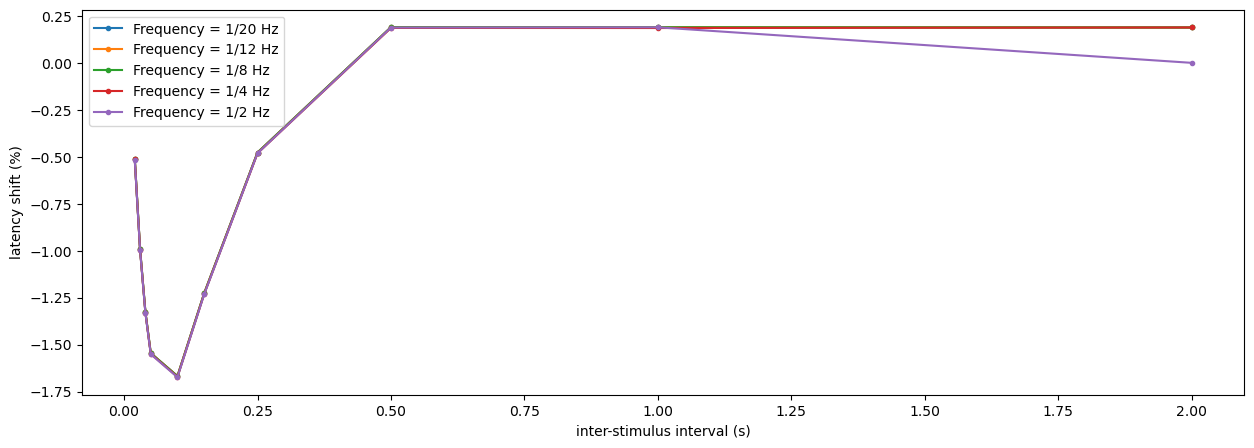

In [5]:
#recovery cycle with different background frequency
data_stim1=stimulationProtocols.protDP(20)

relLatency1=convo.convolution_1D(data_stim1,0.01,8100, convo.memory_1D, "Recovery Cycle")

data_stim2=stimulationProtocols.protDP(12)
relLatency2=convo.convolution_1D(data_stim2,0.01,8100, convo.memory_1D, "Recovery Cycle")

data_stim3=stimulationProtocols.protDP(8)
relLatency3=convo.convolution_1D(data_stim3,0.01,8100, convo.memory_1D, "Recovery Cycle")

data_stim4=stimulationProtocols.protDP(4)
relLatency4=convo.convolution_1D(data_stim4,0.01,8100, convo.memory_1D, "Recovery Cycle")

data_stim5=stimulationProtocols.protDP(2)
relLatency5=convo.convolution_1D(data_stim5,0.01,8100, convo.memory_1D, "Recovery Cycle")

plt.figure(figsize=(15,5)) 
plt.plot(data_stim1, relLatency1, marker='.', linestyle='none', label="Frequency = 1/20 Hz")
plt.plot(data_stim2, relLatency2, marker='.', linestyle='none', label="Frequency = 1/12 Hz")
plt.plot(data_stim3, relLatency3, marker='.', linestyle='none', label="Frequency = 1/8 Hz")
plt.plot(data_stim4, relLatency4, marker='.', linestyle='none', label="Frequency = 1/4 Hz")
plt.plot(data_stim5, relLatency5, marker='.', linestyle='none', label="Frequency = 1/2 Hz")
plt.xlabel("time (s)")
plt.ylabel("latency (%)")
plt.legend()
plt.show()
    
fig, ax=plt.subplots(figsize=(15,5))

extras=[2, 1, 0.5, 0.25, 0.15, 0.1, 0.05, 0.04, 0.03, 0.02]

plt.plot(extras[::-1], plot.getRecoveryCycle(relLatency1)[::-1], marker='.', label="Frequency = 1/20 Hz")
plt.plot(extras[::-1], plot.getRecoveryCycle(relLatency2)[::-1], marker='.', label="Frequency = 1/12 Hz")
plt.plot(extras[::-1], plot.getRecoveryCycle(relLatency3)[::-1], marker='.', label="Frequency = 1/8 Hz")
plt.plot(extras[::-1], plot.getRecoveryCycle(relLatency4)[::-1], marker='.', label="Frequency = 1/4 Hz")
plt.plot(extras[::-1], plot.getRecoveryCycle(relLatency5)[::-1], marker='.', label="Frequency = 1/2 Hz")

plt.xlabel("inter-stimulus interval (s)")
plt.ylabel("latency shift (%)")
plt.legend()
plt.show()


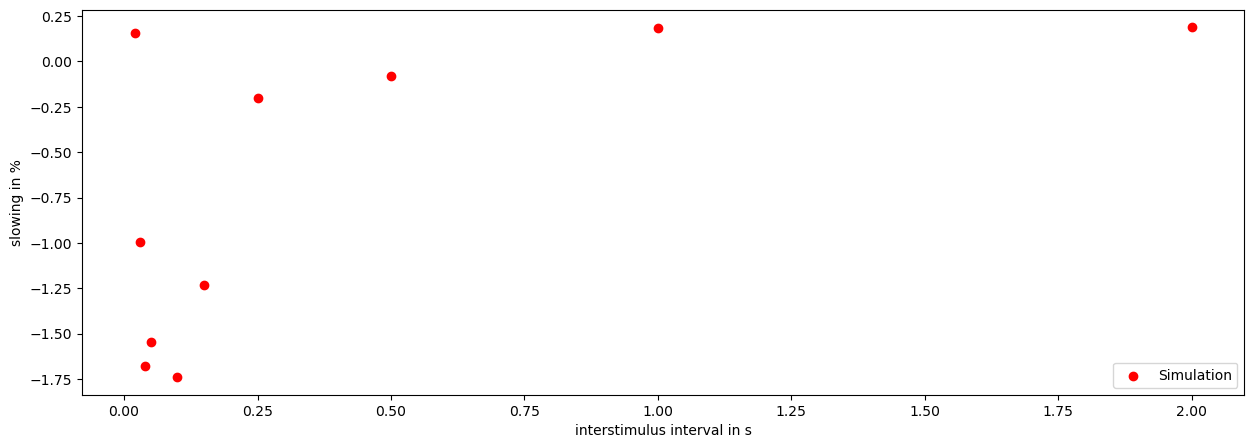

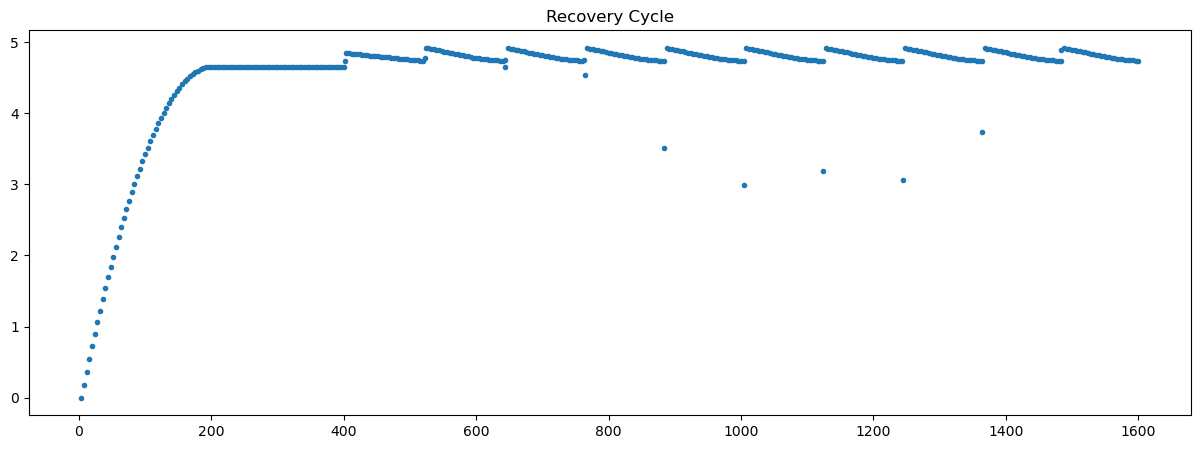

In [6]:
#Recovery Cycle with noise
data_stim=stimulationProtocols.protRecNoise()

relLatency=convo.convolution_1D(data_stim,0.01,1650, convo.memory_1D, "Recovery Cycle")
relLatency2=relLatency

#plotten  
fig, ax=plt.subplots(figsize=(15,5))
extraOriginal=[2, 1, 0.5, 0.25, 0.15, 0.1, 0.05, 0.04, 0.03, 0.02]

data_sim=relLatency
numberPrevPulses=100
numberRegPulses=30
if data_sim is not None:
    l=data_sim
    recoveryCycle2=[]
    
    for i in range(numberPrevPulses-1,len(l)-2,numberRegPulses+1):
        recoveryCycle2.append(l[i+2]-l[i])

    plt.scatter(extras[::-1], recoveryCycle2[::-1], label="Simulation", color="red")
    plt.xlabel("interstimulus interval in s")
    plt.ylabel("slowing in %")
    plt.legend()
    plt.show()


plt.figure(figsize=(15,5)) 
plt.plot(data_stim, relLatency, marker='.', linestyle='none')
plt.title("Recovery Cycle")
plt.show()


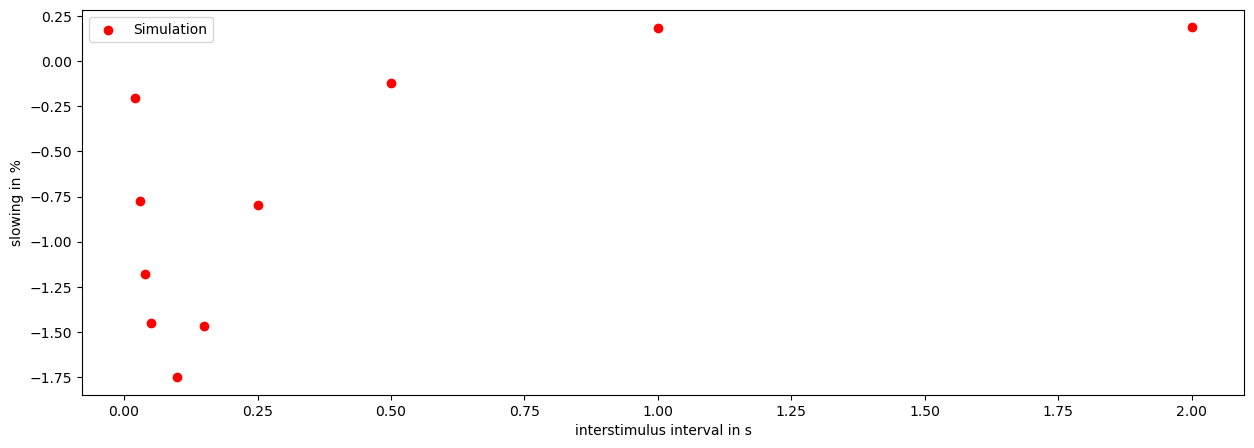

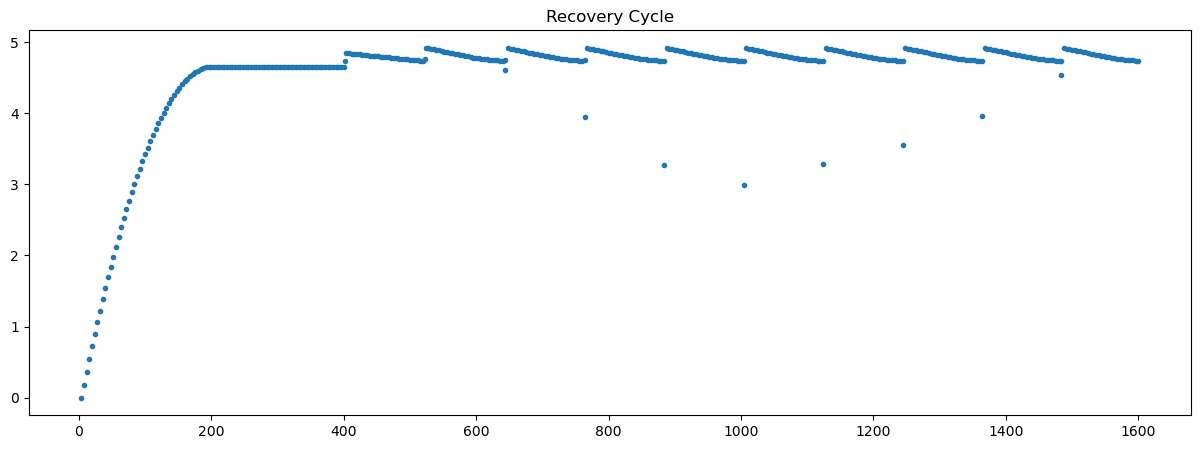

In [7]:
#Recovery Cycle values in between
data_stim=stimulationProtocols.protRecBetween()
relLatency=convo.convolution_1D(data_stim,0.005,1650, convo.memory_1D, "Recovery Cycle")
relLatency3=relLatency

#plotten  
fig, ax=plt.subplots(figsize=(15,5))
data_sim=relLatency
numberPrevPulses=100
numberRegPulses=30
if data_sim is not None:
    l=data_sim
    recoveryCycle3=[]
    
    for i in range(numberPrevPulses-1,len(l)-2,numberRegPulses+1):
        recoveryCycle3.append(l[i+2]-l[i])

    plt.scatter(extras[::-1], recoveryCycle3[::-1], label="Simulation", color="red")

    plt.xlabel("interstimulus interval in s")
    plt.ylabel("slowing in %")
    plt.legend()
    plt.show()


plt.figure(figsize=(15,5)) 
plt.plot(data_stim, relLatency, marker='.', linestyle='none')
plt.title("Recovery Cycle")
plt.show()


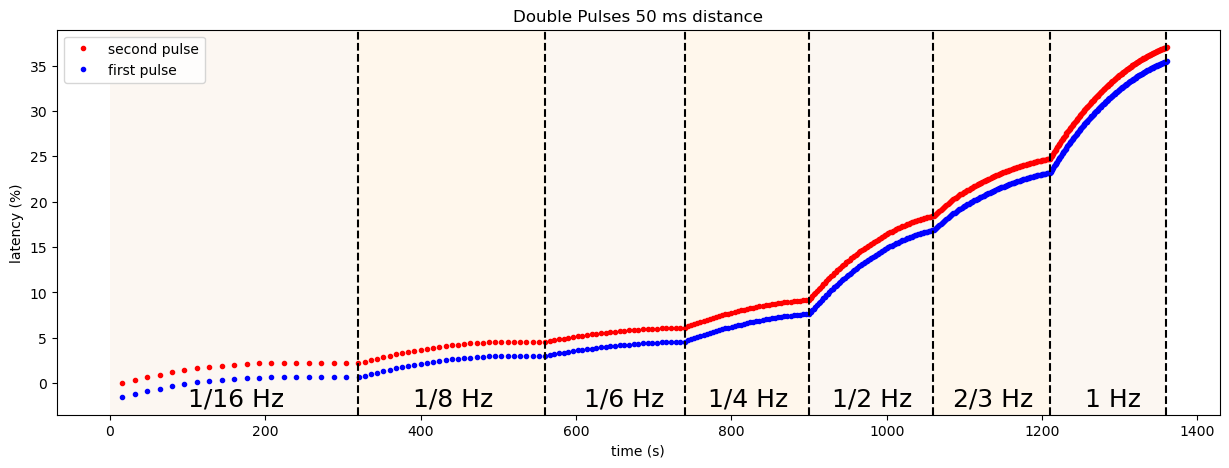

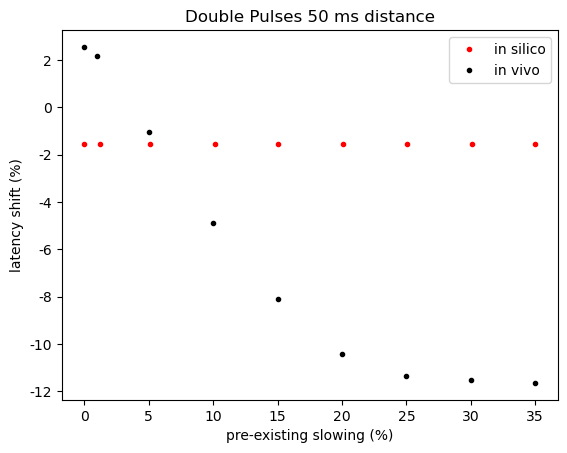

In [9]:
#double pulses, distance 50ms
data_stim=stimulationProtocols.setStimulationProtocol("DPNew")
relLatency=convo.convolution_1D(data_stim,0.01,1650, convo.memory_1D, "Double Pulses")
relLatency=np.array(relLatency)

plt.figure(figsize=(15,5)) 
plt.plot(data_stim[::2], relLatency[::2], 'r.', label="second pulse") 
plt.plot(data_stim[1::2], relLatency[1::2], 'b.', label="first pulse") 
plt.title("Double Pulses 50 ms distance")
plt.xlabel("time (s)")
plt.ylabel("latency (%)")
plt.legend()

plt.text(100, -2.5, "1/16 Hz", fontsize=18)
plt.text(390, -2.5, "1/8 Hz", fontsize=18)
plt.text(610, -2.5, "1/6 Hz", fontsize=18)
plt.text(770, -2.5, "1/4 Hz", fontsize=18)
plt.text(930, -2.5, "1/2 Hz", fontsize=18)
plt.text(1085, -2.5, "2/3 Hz", fontsize=18)
plt.text(1255, -2.5, "1 Hz", fontsize=18)
plt.axvline(x=320, color="black", linestyle="dashed")
plt.axvline(x=560, color="black", linestyle="dashed")
plt.axvline(x=740, color="black", linestyle="dashed")
plt.axvline(x=900, color="black", linestyle="dashed")
plt.axvline(x=1060, color="black", linestyle="dashed")
plt.axvline(x=1210, color="black", linestyle="dashed")
plt.axvline(x=1360, color="black", linestyle="dashed")
plt.axvspan(0, 320, facecolor='#faf0e6', alpha=0.5)
plt.axvspan(320, 560, facecolor='#fff0db', alpha=0.5)
plt.axvspan(560, 740, facecolor='#faf0e6', alpha=0.5)
plt.axvspan(740, 900, facecolor='#fff0db', alpha=0.5)
plt.axvspan(900, 1060, facecolor='#faf0e6', alpha=0.5)
plt.axvspan(1060, 1210, facecolor='#fff0db', alpha=0.5)
plt.axvspan(1210, 1360, facecolor='#faf0e6', alpha=0.5)

plt.show()

plot.plotDoublePulses50(relLatency, savefile="")


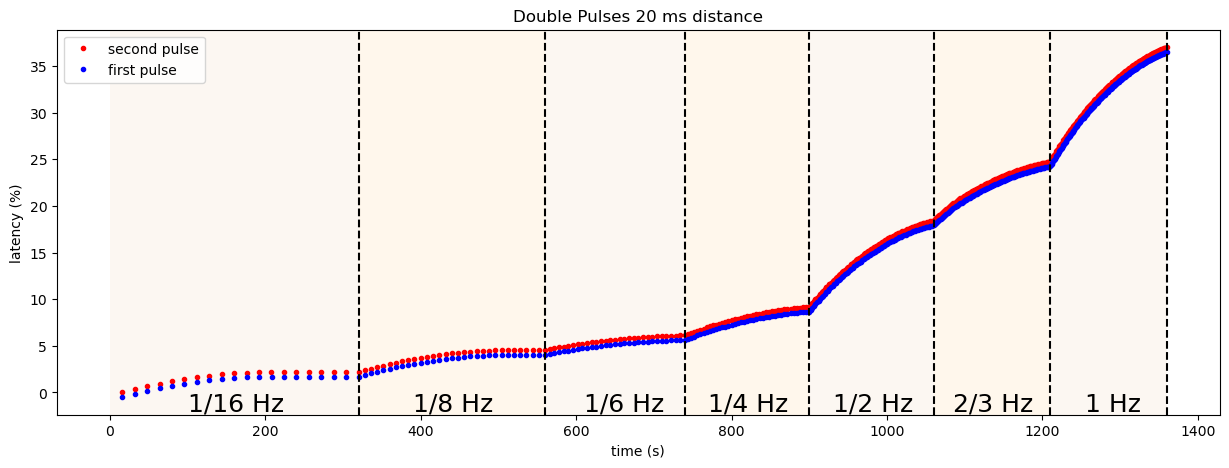

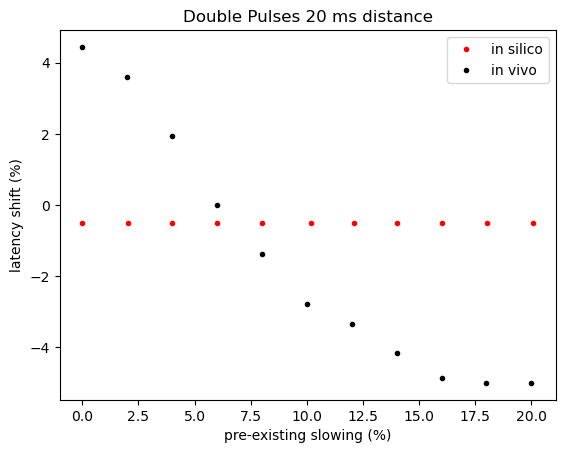

In [11]:
#double pulses, distance 20ms
impulses=stimulationProtocols.setStimulationProtocol("DPNew2")
relLatency=convo.convolution_1D(impulses,0.01,1650, convo.memory_1D, "Double Pulses")
plt.figure(figsize=(15,5)) 
plt.plot(impulses[::2], relLatency[::2], 'r.', label="second pulse") 
plt.plot(impulses[1::2], relLatency[1::2], 'b.', label="first pulse")
plt.title("Double Pulses 20 ms distance")
plt.xlabel("time (s)")
plt.ylabel("latency (%)")
plt.legend()

plt.text(100, -2, "1/16 Hz", fontsize=18)
plt.text(390, -2, "1/8 Hz", fontsize=18)
plt.text(610, -2, "1/6 Hz", fontsize=18)
plt.text(770, -2, "1/4 Hz", fontsize=18)
plt.text(930, -2, "1/2 Hz", fontsize=18)
plt.text(1085, -2, "2/3 Hz", fontsize=18)
plt.text(1255, -2, "1 Hz", fontsize=18)
plt.axvline(x=320, color="black", linestyle="dashed")
plt.axvline(x=560, color="black", linestyle="dashed")
plt.axvline(x=740, color="black", linestyle="dashed")
plt.axvline(x=900, color="black", linestyle="dashed")
plt.axvline(x=1060, color="black", linestyle="dashed")
plt.axvline(x=1210, color="black", linestyle="dashed")
plt.axvline(x=1360, color="black", linestyle="dashed")
plt.axvspan(0, 320, facecolor='#faf0e6', alpha=0.5)
plt.axvspan(320, 560, facecolor='#fff0db', alpha=0.5)
plt.axvspan(560, 740, facecolor='#faf0e6', alpha=0.5)
plt.axvspan(740, 900, facecolor='#fff0db', alpha=0.5)
plt.axvspan(900, 1060, facecolor='#faf0e6', alpha=0.5)
plt.axvspan(1060, 1210, facecolor='#fff0db', alpha=0.5)
plt.axvspan(1210, 1360, facecolor='#faf0e6', alpha=0.5)
plt.show()

plot.plotDoublePulses20(relLatency, savefile="")
